# Proyecto final: bono convertible de Coca-Cola (KO)
**Productos Derivados · Equipo 8:** Maria Cecilia Cantú, Melissa Arizoca y Valeria Acosta

Este notebook replica en Python los cálculos principales del proyecto (el reporte completo está en R Markdown):

1. Descarga de datos (Yahoo Finance) y datos exportados de LSEG
2. Volatilidad histórica y GARCH(1,1)
3. Valuación del convertible con Black-Scholes (bono simple + opción call con dividendo)
4. Árbol binomial del convertible (conversión en cualquier momento)
5. Griegas
6. Call spread de 25% a 60% (como Molson Coors)
7. Escenarios: sensibilidad, Monte Carlo con GARCH y cobertura de tasa con futuros

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/valeriaacostaleal/Productos-Derivados/blob/main/Proyecto_Final/05_Python/Proyecto_Final_KO.ipynb)

**Cómo correrlo en Colab:** ejecutar las celdas en orden. La primera clona el repositorio para tener los archivos de LSEG.

In [1]:
# En Colab: clonar el repositorio con los datos de LSEG (si ya se corrió, no pasa nada)
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('Productos-Derivados'):
    !git clone -q https://github.com/valeriaacostaleal/Productos-Derivados

# Carpeta con los archivos exportados de LSEG
candidatas = ['Productos-Derivados/Proyecto_Final/03_Reporte_Reproducible/datos', '../03_Reporte_Reproducible/datos', 'datos']
RUTA = next((c for c in candidatas if os.path.exists(os.path.join(c, 'KO_precios_5a.xlsx'))), 'datos')
print('Datos en:', RUTA)

Datos en: ../03_Reporte_Reproducible/datos


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq, minimize

pd.options.display.float_format = '{:,.4f}'.format
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['axes.grid'] = True

## 1. Datos

Primero intentamos **descargar** el precio de KO de Yahoo Finance. Si no hay conexión, usamos el archivo exportado de LSEG (Price History, 5 años). Los demás supuestos vienen de pantallas de LSEG Workspace.

Fuente: LSEG (Price History exportado) | 1255 días | 01-Nov-2021 a 30-Oct-2026


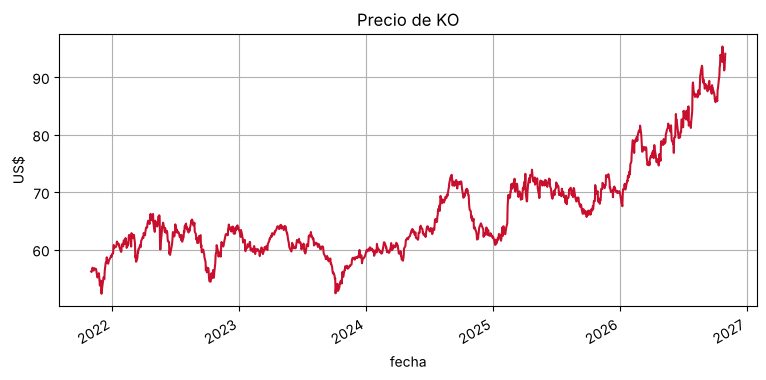

In [3]:
def precios_lseg(ruta):
    x = pd.read_excel(os.path.join(ruta, 'KO_precios_5a.xlsx'), header=None)
    i = x.index[x[0] == 'Exchange Date'][0]
    p = x.iloc[i + 1:, :2].copy(); p.columns = ['fecha', 'cierre']
    p['fecha'] = pd.to_datetime(p['fecha']); p['cierre'] = pd.to_numeric(p['cierre'])
    return p.dropna().sort_values('fecha').set_index('fecha')['cierre']

try:
    import yfinance as yf
    descarga = yf.download('KO', start='2021-11-01', end='2026-10-31', auto_adjust=False, progress=False)['Close'].squeeze().dropna()
    if len(descarga) < 1000: raise ValueError('pocos datos')
    precios, fuente = descarga, 'Yahoo Finance'
except Exception as e:
    precios, fuente = precios_lseg(RUTA), 'LSEG (Price History exportado)'

print(f'Fuente: {fuente} | {len(precios)} días | {precios.index.min():%d-%b-%Y} a {precios.index.max():%d-%b-%Y}')
precios.plot(title='Precio de KO', color='#C8102E'); plt.ylabel('US$'); plt.show()

In [4]:
# ---- Supuestos de mercado (LSEG Workspace) ----
S       = 92.71                       # precio de KO usado en el caso base (cierre del 23-oct-2026)
q       = 0.0229                      # rendimiento por dividendo (Overview)
r       = (0.047852 + 0.048692) / 2   # Treasuries a 5 y 7 años (US5YT=RR, US7YT=RR): tasa a 6 años
iv_2029 = 0.2167                      # volatilidad implícita de la call de KO a ene-2029, strike 115 (Derivatives > Options)
T, prima, emision = 6, 0.25, 3000     # años, prima de conversión, millones de USD

# Tasa del bono simple: rendimiento de los bonos de KO en dólares que vencen en ~5 años (Debt Structure)
b = pd.read_excel(os.path.join(RUTA, 'KO_bonos.xlsx'), sheet_name='Bonds', skiprows=1)
b['plazo'] = (pd.to_datetime(b['Maturity Date']) - pd.Timestamp('2026-10-25')).dt.days / 365.25
usd = b[(b['Currency'] == 'US Dollar') & (b['Instrument Type'] == 'Note') & (b['Amount Outstanding'] > 0)]
y_bono = usd[usd['plazo'].between(4.3, 5.3)]['Yield'].mean() / 100

print(f'Tasa libre de riesgo a 6 años: {r:.2%} | tasa del bono simple de KO: {y_bono:.2%} | spread: {(y_bono - r) * 1e4:.0f} pb')

Tasa libre de riesgo a 6 años: 4.83% | tasa del bono simple de KO: 5.09% | spread: 27 pb


## 2. Volatilidad: histórica y GARCH(1,1)

GARCH(1,1): varianza de mañana = ω + α·(rendimiento de hoy)² + β·(varianza de hoy). Lo estimamos por máxima verosimilitud.

In [5]:
u = 100 * np.log(precios).diff().dropna().values      # rendimientos diarios en %
vol_hist = u[-252:].std(ddof=1) * np.sqrt(252) / 100

def varianzas(w, a, b, u):
    s2 = np.empty_like(u); s2[0] = u.var()
    for t in range(1, len(u)):
        s2[t] = w + a * u[t - 1] ** 2 + b * s2[t - 1]
    return s2

def nll(th):
    w = np.exp(th[0]); a = 1 / (1 + np.exp(-th[1])); b = (1 - a) / (1 + np.exp(-th[2]))
    s2 = varianzas(w, a, b, u)
    return 0.5 * np.sum(np.log(s2[1:]) + u[1:] ** 2 / s2[1:])

mejor = None
for a0, b0 in [(0.05, 0.90), (0.10, 0.85), (0.05, 0.80)]:
    th0 = [np.log(u.var() * (1 - a0 - b0)), np.log(a0 / (1 - a0)), np.log((b0 / (1 - a0)) / (1 - b0 / (1 - a0)))]
    res = minimize(nll, th0, method='Nelder-Mead', options={'maxiter': 5000, 'xatol': 1e-8, 'fatol': 1e-8})
    if mejor is None or res.fun < mejor.fun: mejor = res
w = np.exp(mejor.x[0]); a = 1 / (1 + np.exp(-mejor.x[1])); b = (1 - a) / (1 + np.exp(-mejor.x[2]))
VL = w / (1 - a - b); s2 = varianzas(w, a, b, u); s2_man = w + a * u[-1] ** 2 + b * s2[-1]
anual = lambda v: np.sqrt(v * 252) / 100
vol_garch_6a = anual(np.mean(VL + (a + b) ** np.arange(1512) * (s2_man - VL)))

pd.DataFrame({'Valor': [w, a, b, a + b, anual(VL), anual(s2_man), np.log(0.5) / np.log(a + b), vol_hist, vol_garch_6a]},
             index=['omega', 'alfa', 'beta', 'persistencia', 'vol. largo plazo', 'vol. para mañana', 'vida media (días)',
                    'vol. histórica 1 año', 'vol. GARCH promedio 6 años'])

,Valor
omega,0.0495
alfa,0.0702
beta,0.8894
persistencia,0.9597
vol. largo plazo,0.1759
vol. para mañana,0.2092
vida media (días),16.8407
vol. histórica 1 año,0.1896
vol. GARCH promedio 6 años,0.1765


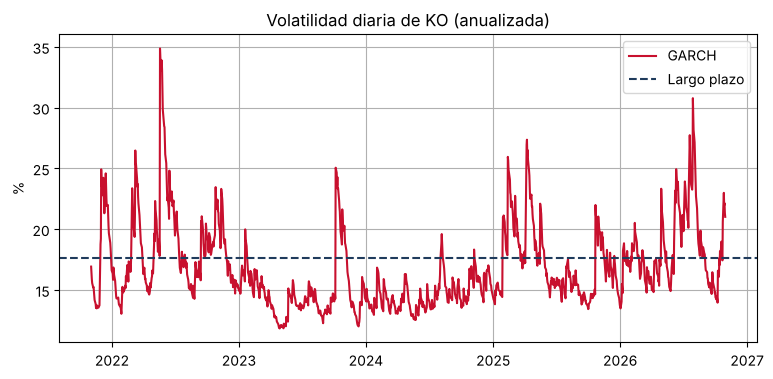

In [6]:
plt.plot(precios.index[1:], anual(s2) * 100, color='#C8102E', label='GARCH')
plt.axhline(anual(VL) * 100, color='#1F3B5C', ls='--', label='Largo plazo')
plt.title('Volatilidad diaria de KO (anualizada)'); plt.ylabel('%'); plt.legend(); plt.show()

**Lectura.** α + β cerca de 0.96: la volatilidad de KO tiene memoria (un choque tarda semanas en bajar a la mitad) y regresa a un nivel de largo plazo cercano a 17.6%. Para el convertible usamos como caso base la **volatilidad implícita** (21.7%), porque es la que cobra el mercado, y el GARCH queda como escenario.

## 3. Convertible con Black-Scholes

Convertible = **bono simple + opción call**. Con prima de 25%, cada bono de US$1,000 se puede cambiar por 1,000 / (1.25 × S) acciones. El **cupón de equilibrio** es el que hace que bono simple + opción = US$1,000.

In [7]:
def bs_call(S, K, T, r, q, s):
    d1 = (np.log(S / K) + (r - q + s ** 2 / 2) * T) / (s * np.sqrt(T)); d2 = d1 - s * np.sqrt(T)
    return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def valor_bono(cupon, y, T=6):
    n, i = int(T * 2), y / 2
    return sum(1000 * cupon / 2 / (1 + i) ** k for k in range(1, n + 1)) + 1000 / (1 + i) ** n

def valuar(prima=0.25, q=q, sigma=iv_2029, S0=S):
    K = S0 * (1 + prima); n_acc = 1000 / K
    opcion = bs_call(S0, K, T, r, q, sigma) * n_acc
    cupon = brentq(lambda c: valor_bono(c, y_bono) - (1000 - opcion), -0.1, 0.2)
    return dict(K=K, acciones_por_bono=n_acc, opcion=opcion, bono=1000 - opcion, cupon=cupon)

casos = pd.DataFrame({'Base (vol. implícita)': valuar(), 'Vol. histórica': valuar(sigma=vol_hist),
                      'Vol. GARCH 6 años': valuar(sigma=vol_garch_6a), 'Sin dividendo': valuar(q=0)}).T
base = casos.loc['Base (vol. implícita)']
ahorro = (y_bono - base['cupon']) * emision
casos

,K,acciones_por_bono,opcion,bono,cupon
Base (vol. implícita),115.8875,8.6291,127.0023,872.9977,0.0261
Vol. histórica,115.8875,8.6291,108.6434,891.3566,0.0297
Vol. GARCH 6 años,115.8875,8.6291,99.7541,900.2459,0.0314
Sin dividendo,115.8875,8.6291,189.0250,810.9750,0.0140


In [8]:
print(f"Cupón de equilibrio (caso base): {base['cupon']:.2%} vs. {y_bono:.2%} de un bono simple")
print(f"Ahorro de intereses: US${ahorro:,.1f} millones al año")
print(f"Molson (2007): cupón de equilibrio 1.93%, opción US$191.5 por bono (sin dividendo)")

Cupón de equilibrio (caso base): 2.61% vs. 5.09% de un bono simple
Ahorro de intereses: US$74.5 millones al año
Molson (2007): cupón de equilibrio 1.93%, opción US$191.5 por bono (sin dividendo)


**Lectura.** Con prima de 25% y volatilidad implícita, el cupón de equilibrio es de alrededor de 2.6%: unos 2.5 puntos menos que un bono simple de KO. Si **no** se toma en cuenta el dividendo, la opción parece valer más y el cupón sale demasiado bajo; esa es la diferencia más importante contra Molson.

## 4. Árbol binomial del convertible

Árbol CRR con el método de Tsiveriotis-Fernandes: la parte que se convertirá en acciones se descuenta a la tasa libre de riesgo y la parte en efectivo a la tasa de KO. En cada nodo el inversionista decide si convierte.

Con el cupón de Black-Scholes (2.61%) el árbol vale US$1,004.46
Cupón de equilibrio con el árbol (300 pasos): 2.52%


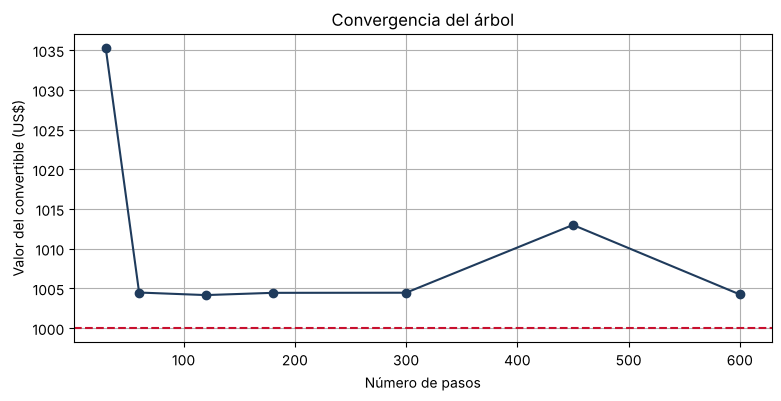

In [9]:
def arbol_convertible(S, n_acc, T, r, q, s, yc, cupon, pasos_anio=50, nominal=1000):
    N = int(T * pasos_anio); dt = 1 / pasos_anio
    u_ = np.exp(s * np.sqrt(dt)); d_ = 1 / u_; p = (np.exp((r - q) * dt) - d_) / (u_ - d_)
    da, dd = np.exp(-r * dt), np.exp(-yc * dt)
    pagos = min(2, pasos_anio); cada = pasos_anio // pagos; pago = nominal * cupon / pagos
    St = S * u_ ** np.arange(N, -1, -1) * d_ ** np.arange(0, N + 1)
    conv = n_acc * St > nominal
    E = np.where(conv, n_acc * St, 0.0); D = np.where(conv, 0.0, nominal) + pago
    for i in range(N - 1, -1, -1):
        Si = S * u_ ** np.arange(i, -1, -1) * d_ ** np.arange(0, i + 1)
        E = da * (p * E[:-1] + (1 - p) * E[1:]); D = dd * (p * D[:-1] + (1 - p) * D[1:])
        if i > 0 and i % cada == 0: D = D + pago
        vc = n_acc * Si; c = vc > E + D
        E = np.where(c, vc, E); D = np.where(c, 0.0, D)
    return E[0] + D[0]

n_acc = base['acciones_por_bono']
v_arbol = arbol_convertible(S, n_acc, T, r, q, iv_2029, y_bono, base['cupon'])
cupon_arbol = brentq(lambda c: arbol_convertible(S, n_acc, T, r, q, iv_2029, y_bono, c) - 1000, 0, 0.08)
print(f'Con el cupón de Black-Scholes ({base["cupon"]:.2%}) el árbol vale US${v_arbol:,.2f}')
print(f'Cupón de equilibrio con el árbol (300 pasos): {cupon_arbol:.2%}')

pasos = [5, 10, 20, 30, 50, 75, 100]
conv = [arbol_convertible(S, n_acc, T, r, q, iv_2029, y_bono, base['cupon'], k) for k in pasos]
plt.plot([k * T for k in pasos], conv, marker='o', color='#1F3B5C'); plt.axhline(1000, color='#C8102E', ls='--')
plt.title('Convergencia del árbol'); plt.xlabel('Número de pasos'); plt.ylabel('Valor del convertible (US$)'); plt.show()

**Lectura.** El árbol da un valor un poco mayor que Black-Scholes porque permite convertir en cualquier momento (opción americana), así que el cupón de equilibrio baja un poco, a cerca de 2.5%. Los dos métodos coinciden en el orden de magnitud: el resultado es robusto.

## 5. Griegas

Para toda la emisión (millones de acciones en que se puede convertir), desde el punto de vista de KO.

In [10]:
def griegas(S, K, T, r, q, s):
    d1 = (np.log(S / K) + (r - q + s ** 2 / 2) * T) / (s * np.sqrt(T)); d2 = d1 - s * np.sqrt(T)
    return dict(Valor=bs_call(S, K, T, r, q, s), Delta=np.exp(-q * T) * norm.cdf(d1),
                Gamma=np.exp(-q * T) * norm.pdf(d1) / (S * s * np.sqrt(T)),
                Vega=S * np.exp(-q * T) * norm.pdf(d1) * np.sqrt(T) / 100,
                Theta=(-S * np.exp(-q * T) * norm.pdf(d1) * s / (2 * np.sqrt(T)) + q * S * np.exp(-q * T) * norm.cdf(d1)
                       - r * K * np.exp(-r * T) * norm.cdf(d2)) / 365,
                Rho=K * T * np.exp(-r * T) * norm.cdf(d2) / 100)

K1, K2 = S * 1.25, S * 1.60
n_tot = emision / K1
g = pd.DataFrame({'Opción del convertible (KO vende)': {k: -v * n_tot for k, v in griegas(S, K1, T, r, q, iv_2029).items()},
                  'Calls a 125% (KO compra)': {k: v * n_tot for k, v in griegas(S, K1, T, r, q, iv_2029).items()},
                  'Warrants a 160% (KO vende)': {k: -v * n_tot for k, v in griegas(S, K2, T, r, q, iv_2029).items()}}).T
g.loc['Neto para KO'] = g.sum()
g

,Valor,Delta,Gamma,Vega,Theta,Rho
Opción del convertible (KO vende),-381.0068,-12.4650,-0.1813,-20.2653,0.1302,-46.4773
Calls a 125% (KO compra),381.0068,12.4650,0.1813,20.2653,-0.1302,46.4773
Warrants a 160% (KO vende),-215.9007,-8.3366,-0.1730,-19.3379,0.1208,-33.4194
Neto para KO,-215.9007,-8.3366,-0.1730,-19.3379,0.1208,-33.4194


**Lectura.** La opción del convertible tiene delta de ~0.48: es como si KO hubiera vendido a futuro unos 12.5 millones de acciones. Con el call spread, la exposición baja a unos 8.3 millones (solo la parte arriba de 160%). La vega negativa dice que a KO le conviene emitir cuando la volatilidad está alta, porque los inversionistas pagan más por la opción.

## 6. Call spread (prima efectiva de 60%)

KO compra calls a 125% (cubren las conversiones) y vende warrants a 160%. Así solo entrega acciones nuevas si KO pasa de 160%.

In [11]:
costo_calls = bs_call(S, K1, T, r, q, iv_2029) * n_tot
ingreso_w = bs_call(S, K2, T, r, q, iv_2029) * n_tot
neto = ingreso_w - costo_calls
pd.DataFrame({'Millones USD': [-costo_calls, ingreso_w, neto], '% de la emisión': [-costo_calls / emision, ingreso_w / emision, neto / emision]},
             index=['Compra de calls 125%', 'Venta de warrants 160%', 'Costo neto'])

,Millones USD,% de la emisión
Compra de calls 125%,-381.0068,-0.1270
Venta de warrants 160%,215.9007,0.0720
Costo neto,-165.1061,-0.0550


Costo neto: 5.5% de la emisión (Molson: 8.6%). Se recupera en 2.2 años de ahorro en intereses.


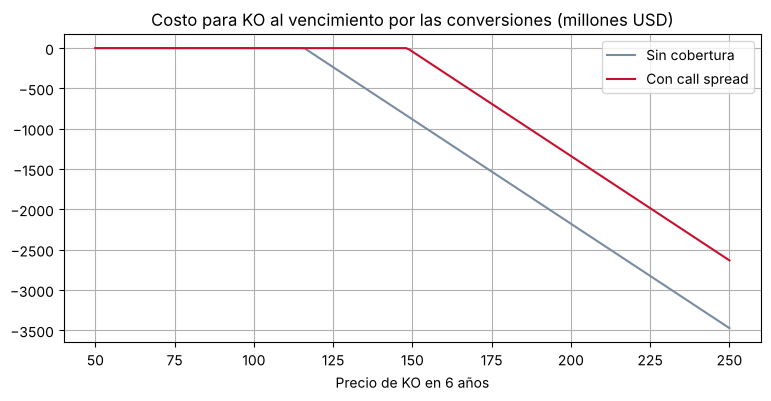

In [12]:
print(f'Costo neto: {-neto / emision:.1%} de la emisión (Molson: 8.6%). Se recupera en {-neto / ahorro:.1f} años de ahorro en intereses.')
x = np.linspace(50, 250, 201)
plt.plot(x, -np.maximum(x - K1, 0) * n_tot, label='Sin cobertura', color='#7a8ca0')
plt.plot(x, -np.maximum(x - K2, 0) * n_tot, label='Con call spread', color='#C8102E')
plt.title('Costo para KO al vencimiento por las conversiones (millones USD)'); plt.xlabel('Precio de KO en 6 años'); plt.legend(); plt.show()

## 7. Escenarios

### 7.1 Sensibilidad del cupón a la prima y a la volatilidad

In [13]:
vols = {'GARCH 6 años': vol_garch_6a, 'Histórica': vol_hist, 'Implícita (base)': iv_2029, 'Estrés 25%': 0.25}
sens = pd.DataFrame({nom: [valuar(p, sigma=v)['cupon'] for p in [0.15, 0.20, 0.25, 0.30, 0.40, 0.60]] for nom, v in vols.items()},
                    index=['15%', '20%', '25%', '30%', '40%', '60%'])
sens.index.name = 'Prima'
sens.style.format('{:.2%}')

,GARCH 6 años,Histórica,Implícita (base),Estrés 25%
Prima,,,,
15%,2.48%,2.30%,1.92%,1.46%
20%,2.84%,2.66%,2.29%,1.84%
25%,3.14%,2.97%,2.61%,2.17%
30%,3.41%,3.24%,2.89%,2.47%
40%,3.83%,3.68%,3.36%,2.96%
60%,4.38%,4.26%,4.00%,3.66%


### 7.2 Monte Carlo con GARCH: ¿qué tan probable es que conviertan?

Probabilidad de conversión (KO > 115.89): 35.2%
Probabilidad de pasar el strike de los warrants (> 148.34): 17.0%
Opción por acción: Monte Carlo 11.53 vs Black-Scholes con vol. GARCH 11.56


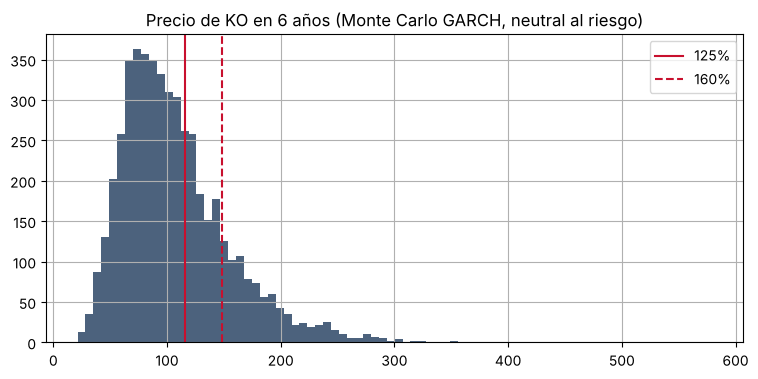

In [14]:
rng = np.random.default_rng(2026)
n_sim, dias = 5000, 252 * T
Ssim = np.full(n_sim, S); v = np.full(n_sim, s2_man)
for d in range(dias):
    e = np.sqrt(v) * rng.standard_normal(n_sim)
    Ssim *= np.exp(((r - q) * 100 / 252 - 0.5 * v / 100 + e) / 100)
    v = w + a * e ** 2 + b * v
print(f'Probabilidad de conversión (KO > {K1:.2f}): {np.mean(Ssim > K1):.1%}')
print(f'Probabilidad de pasar el strike de los warrants (> {K2:.2f}): {np.mean(Ssim > K2):.1%}')
print(f'Opción por acción: Monte Carlo {np.exp(-r * T) * np.maximum(Ssim - K1, 0).mean():.2f} vs Black-Scholes con vol. GARCH {bs_call(S, K1, T, r, q, vol_garch_6a):.2f}')
plt.hist(Ssim, bins=80, color='#1F3B5C', alpha=0.8); plt.axvline(K1, color='#C8102E', label='125%'); plt.axvline(K2, color='#C8102E', ls='--', label='160%')
plt.title('Precio de KO en 6 años (Monte Carlo GARCH, neutral al riesgo)'); plt.legend(); plt.show()

### 7.3 Cobertura de tasa con futuros del Tesoro (equivalente al T-lock de Molson)

Futuro a 10 años (TYc1, LSEG 6-nov-2026): 107-03½, tasa implícita 4.75%. Cobertura por duración (Hull 6.4).

In [15]:
def dur_mod(cupon, y, plazo):
    t = np.arange(0.5, plazo + 0.01, 0.5); cf = np.full(len(t), cupon / 2); cf[-1] += 1
    pv = cf / (1 + y / 2) ** (2 * t); return (t * pv).sum() / pv.sum() / (1 + y / 2)

P_bono = emision * 1e6 * base['bono'] / 1000; D_bono = dur_mod(base['cupon'], y_bono, 6)
V_F = (107 + 3.5 / 32) / 100 * 100000; D_F = dur_mod(0.0475, 0.0475, 6.5)     # bono entregable típico de ~6.5 años
N_fut = P_bono * D_bono / (V_F * D_F)
print(f'Bono simple: US${P_bono / 1e6:,.0f} M, duración {D_bono:.2f} | futuro: US${V_F:,.0f} por contrato, duración {D_F:.2f}')
print(f'Contratos a vender: {N_fut:,.0f}')
for pb in [-50, 50]:
    dy = pb / 1e4
    print(f'Tasas {pb:+} pb: bono {-P_bono * D_bono * dy / 1e6:+,.1f} M, futuros {N_fut * V_F * D_F * dy / 1e6:+,.1f} M')

Bono simple: US$2,619 M, duración 5.42 | futuro: US$107,109 por contrato, duración 5.54
Contratos a vender: 23,930
Tasas -50 pb: bono +71.0 M, futuros -71.0 M
Tasas +50 pb: bono -71.0 M, futuros +71.0 M


## 8. Conclusión

* KO puede emitir **US$3,000 millones** en un convertible a 6 años con prima de 25% y un cupón de **2.5% a 2.6%**, contra ~5.1% de un bono simple: un ahorro de unos US$74 millones al año.
* El **call spread** de 25% a 60% cuesta alrededor de 5.5% de la emisión y se paga en poco más de 2 años de ahorro.
* Black-Scholes, árbol binomial y Monte Carlo con GARCH dan resultados muy parecidos.
* Entre la aprobación y la colocación, vender futuros del Tesoro a 10 años fija la tasa (como el T-lock de Molson).
* Ninguna mejora es gratis: bajar el cupón o subir la prima efectiva siempre tiene un costo en derivados.